# Multivariate Linear Regression

In [1]:
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.preprocessing import OrdinalEncoder, StandardScaler, MinMaxScaler, RobustScaler
import statsmodels.api as sm
from sklearn.metrics import r2_score, mean_squared_error
from math import sqrt

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

font = {'size': 14}
matplotlib.rc('font', **font)
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Verdana"]

## Data and Model Import

In [2]:
data_sue = pd.read_csv('data/data_sue.csv')
data_ntl = pd.read_csv('data/data_ntl.csv')

In [3]:
features = ['Black Percentile', 'Hispanic Percentile',
            'White Percentile', 'Median Income Percentile']
label    = 'SUHI'

## Helper Functions

In [4]:
def get_data(dataset):
    Xy = dataset[features+[label]].dropna().copy()
    X  = Xy.copy()[features]
    y  = Xy.copy()[label]

    return X, y

### Feature Importance
We provide feature importance of the linear regression coefficients by standardizing the features.

In [5]:
def standard_transform(X):
    X_transform = X.copy()
    for feature in features:
        X_transform[feature] = StandardScaler().fit_transform(np.array(X_transform[feature]).reshape(-1, 1))
        return X_transform

In [6]:
def robust_transform(X):
    X_transform = X.copy()
    for feature in features:
        X_transform[feature] = RobustScaler().fit_transform(np.array(X_transform[feature]).reshape(-1, 1))
        return X_transform

In [7]:
def minmax_transform(X):
    X_transform = X.copy()
    for feature in features:
        X_transform[feature] = MinMaxScaler().fit_transform(np.array(X_transform[feature]).reshape(-1, 1))
        return X_transform

In [8]:
def get_model(X, y):
    X       = sm.add_constant(X)
    model   = sm.OLS(y, np.asarray(X))
    results = model.fit()
    
    return model, results

In [9]:
def save_results(results, filename):
    summary = pd.DataFrame({'Features': ['Constant']+features, 'Coefficients': np.asarray(results.params), 
                           'LB': np.asarray(results.conf_int()[0]), 'UB': np.asarray(results.conf_int()[1]), 
                           'pval': np.asarray(results.pvalues)})
    summary = summary.round(4)
    summary.to_csv('tables/linear_regression/{}_sociophysical.csv'.format(filename),index=False)
    return

In [10]:
def weighted_effect(X_tranform, feat_imp):
    weighted_X = X_tranform.copy()
    weights    = feat_imp['Coefficients'].to_numpy()
    for i in range(len(features)):
        feature = features[i]
        weight  = weights[i] 
        weighted_X[feature] = weighted_X[feature] * weight
    return weighted_X

In [11]:
def plot_ols_imp(transform='standard'):
    feature_names = ['Black Percentile', 'Hispanic Percentile',
                     'White Percentile', 'Median Income Percentile']
    
    nrows,ncols=2,2
    fig, ax = plt.subplots(nrows, ncols, figsize=(10,10), constrained_layout=True, sharex='col')
    datasets = [data_sue, data_ntl]

    for i in range(nrows):
        X, y = get_data(datasets[i]) # get data
        if transform == 'standard':
            X = standard_transform(X) # transform data
        if transform == 'robust':
            X = robust_transform(X) # transform data
        if transform == 'minmax':
            X = minmax_transform(X) # transform data
        model, results = get_model(X, y) # get model
        #print(results.summary())
        results_df = pd.DataFrame({
            "var": ['Constant'] + features,  
            "coef": results.params,
            "pvals": results.pvalues,
            "conf_lower": results.conf_int()[0],
            "conf_higher": results.conf_int()[1]
        }).round(2)
        display(results_df)
        
        
        feat_imp = pd.DataFrame({'Features': features, 'Feature Names':feature_names, 'Coefficients': np.asarray(results.params[1:]), 
                                 'LB': np.asarray(results.conf_int()[0][1:]), 'UB': np.asarray(results.conf_int()[1][1:])})
        weighted_X = weighted_effect(X, feat_imp)
        feat_imp_sorted = feat_imp.sort_values(by='Coefficients', key=abs, ascending=True)

        # Uneven confidence intervals (errors)
        lower_errors = feat_imp_sorted['LB'].to_numpy()
        upper_errors = feat_imp_sorted['UB'].to_numpy()

        # Asymmetric error values for plotting
        errors = [np.abs(lower_errors), np.abs(upper_errors)]

        # Create the plot with error bars
        ax[i][0].errorbar(np.asarray(feat_imp_sorted['Coefficients']), np.asarray(feat_imp_sorted['Feature Names']), xerr=errors, fmt='o', capsize=5)
        ax[i][0].set_xlabel('Standarized Weights')
        ax[i][0].axvline(0, linestyle='dashed')
        ax[i][0].grid(True)
        method = 'SUE' if i == 0 else 'NTL'
        ax[i][0].set_title(str(i+1) + '(a) ' + method, fontsize=14)

        ax[i][1].boxplot([weighted_X[feature].to_numpy() for feature in feat_imp_sorted['Features'].to_list()], vert=False)
        ax[i][1].axvline(0, linestyle='dashdot')
        ax[i][1].set_xlabel('Effect on SUHI')
        ax[i][1].tick_params(labelleft=False) 
        ax[i][1].grid(True)
        ax[i][1].set_title(str(i+1) + '(b) ' + method, fontsize=14) #+ dataset, fontsize=14)

    plt.savefig('graphs/feature_importance/linear_feature_importance_sociophysical_{}.jpg'.format(transform), bbox_inches='tight', dpi=1000)


## SUE OLS Model Results

In [12]:
X, y = get_data(data_sue)
model, results = get_model(X, y)
y_pred = model.predict(results.params, sm.add_constant(X))
save_results(results, 'SUE')
print(label)
print('R2: {:.3f}'.format(results.rsquared))
print('RMSE: {:.3f}'.format(sqrt(results.mse_total)))
print('MBE: {:.3f}'.format(np.mean(y_pred - y)))

SUHI
R2: 0.178
RMSE: 3.121
MBE: 0.000


## NTL OLS Model Results

In [13]:
X, y = get_data(data_ntl)
model, results = get_model(X, y)
y_pred = model.predict(results.params, sm.add_constant(X))
save_results(results, 'NTL')
print(label)
print('R2: {:.3f}'.format(results.rsquared))
print('RMSE: {:.3f}'.format(sqrt(results.mse_total)))
print('MBE: {:.3f}'.format(np.mean(y_pred - y)))

SUHI
R2: 0.093
RMSE: 3.894
MBE: -0.000


## OLS Feature Importance

,var,coef,pvals,conf_lower,conf_higher
const,Constant,5.68,0.0,5.56,5.79
x1,Black Percentile,0.08,0.0,0.05,0.12
x2,Hispanic Percentile,0.31,0.0,0.20,0.41
x3,White Percentile,-2.98,0.0,-3.13,-2.83
x4,Median Income Percentile,-1.56,0.0,-1.67,-1.44


,var,coef,pvals,conf_lower,conf_higher
const,Constant,5.21,0.0,5.07,5.35
x1,Black Percentile,0.15,0.0,0.10,0.19
x2,Hispanic Percentile,0.63,0.0,0.50,0.76
x3,White Percentile,-2.42,0.0,-2.60,-2.24
x4,Median Income Percentile,-1.32,0.0,-1.46,-1.17


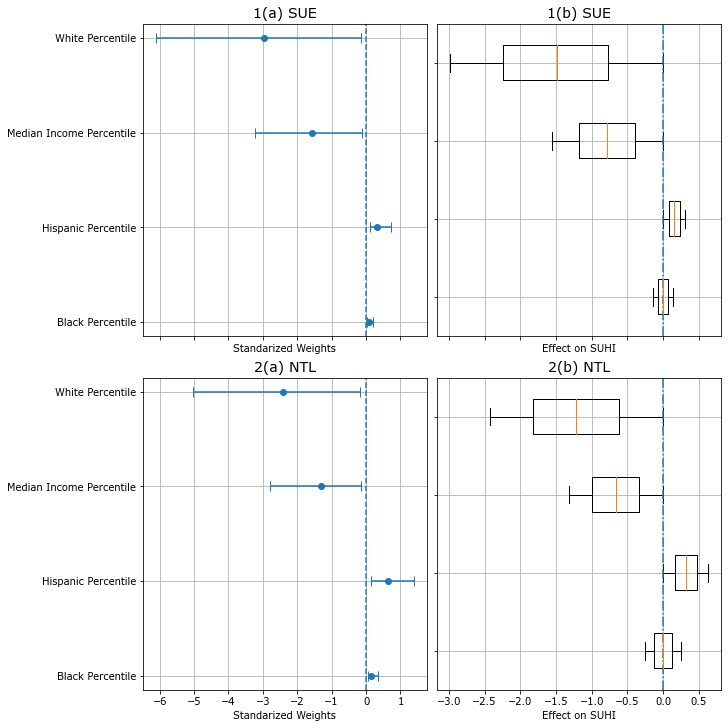

In [14]:
font = {'size': 14}
matplotlib.rc('font', **font)
plot_ols_imp(transform='standard')

                            OLS Regression Results                            
Dep. Variable:                   SUHI   R-squared:                       0.582
Model:                            OLS   Adj. R-squared:                  0.581
Method:                 Least Squares   F-statistic:                     7098.
Date:                Tue, 21 Oct 2025   Prob (F-statistic):               0.00
Time:                        13:08:25   Log-Likelihood:            -1.0729e+05
No. Observations:               51092   AIC:                         2.146e+05
Df Residuals:                   51081   BIC:                         2.147e+05
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          2.0244      0.067     30.116      0.0

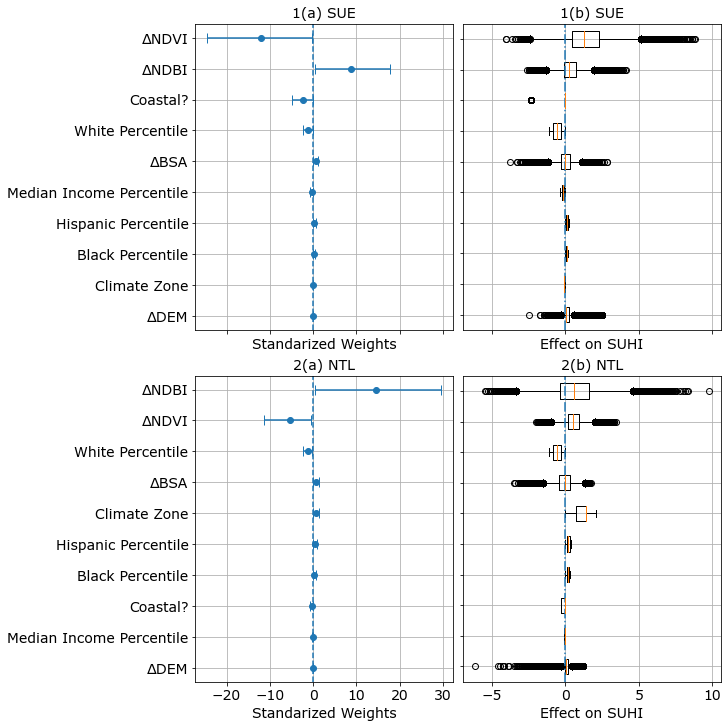

In [21]:
plot_ols_imp(transform='robust')

                            OLS Regression Results                            
Dep. Variable:                   SUHI   R-squared:                       0.582
Model:                            OLS   Adj. R-squared:                  0.581
Method:                 Least Squares   F-statistic:                     7098.
Date:                Tue, 21 Oct 2025   Prob (F-statistic):               0.00
Time:                        13:08:45   Log-Likelihood:            -1.0729e+05
No. Observations:               51092   AIC:                         2.146e+05
Df Residuals:                   51081   BIC:                         2.147e+05
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -1.7747      0.103    -17.289      0.0

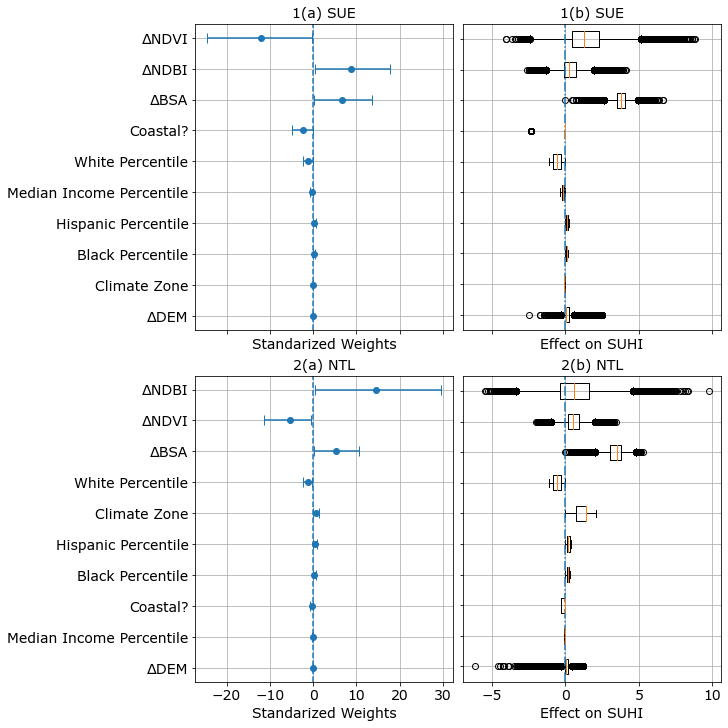

In [22]:
plot_ols_imp(transform='minmax')